# College Majors 2026: Data Cleaning, EDA and Preprocessing
**BUAN 6341 · Group 2** · Prepared by Manoj Elangovan Jayanthi

**Dataset:** [College Majors 2026: Earnings, Debt, Jobs, AI](https://www.kaggle.com/datasets/kylefengkfeng209/college-majors-2026-earnings-debt-jobs-ai) (one row = institution × field of study × credential level)

**What this notebook does**
1. Audits the raw data: variables, types, missing values, duplicates
2. Cleans it, with a row-count log for every step
3. Flags leakage columns that must not be used as predictors
4. Creates one institution-grouped train/test split that both problems share
5. Explores the **regression target** (median earnings 4 years after completion) and the **classification target** (high debt-risk)
6. Builds reusable preprocessing pipelines that are fitted on training data only
7. Summarizes findings and open questions for the group

**To run (Google Colab or Jupyter):** use **Runtime → Run all** (Colab) or **Run All** (Jupyter). Cells depend on each other, so run them in order from the top.
The first code cell finds the data automatically. It looks for `college_majors_2026.csv` (or the Kaggle zip) in the notebook's folder, in `/content` and in your Google Drive. If it can't find the file, it shows an **upload button** in Colab: pick the CSV or the zip you downloaded from Kaggle.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor

OUT_DIR = Path(".")
RANDOM_STATE = 42

pd.set_option("display.max_columns", 80, "display.width", 200, "display.max_colwidth", 70)

# ---- chart style (one consistent look) ----
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "font.size": 9.5, "legend.frameon": False, "axes.axisbelow": True,
})
DIVERGING = LinearSegmentedColormap.from_list("div", [ORANGE, "#f0efec", BLUE])
usd = mtick.FuncFormatter(lambda x, _: f"${x/1000:,.0f}k")
pct = mtick.PercentFormatter(1.0, decimals=0)
def short(s, n=38): return s if len(s) <= n else s[: n - 1] + "…"

In [2]:
# ---- Find the dataset (works in Colab and local Jupyter) ----
import zipfile, glob, os
CSV_NAME = "college_majors_2026.csv"

def find_data():
    # 1) the CSV itself in common places
    for pattern in [CSV_NAME, f"/content/{CSV_NAME}", f"/content/drive/MyDrive/**/{CSV_NAME}", f"**/{CSV_NAME}"]:
        hits = glob.glob(pattern, recursive=True)
        if hits:
            return Path(hits[0])
    # 2) a Kaggle zip (e.g. archive.zip / archive (5).zip) → extract the CSV
    for z in glob.glob("*.zip") + glob.glob("/content/*.zip") + glob.glob("/content/drive/MyDrive/**/*.zip", recursive=True):
        with zipfile.ZipFile(z) as zf:
            if CSV_NAME in zf.namelist():
                zf.extract(CSV_NAME, "."); return Path(CSV_NAME)
    return None

DATA_PATH = find_data()
if DATA_PATH is None:
    try:
        from google.colab import files          # only exists in Colab
        print("Dataset not found. Choose college_majors_2026.csv (or the Kaggle .zip) to upload…")
        uploaded = files.upload()
        DATA_PATH = find_data()
    except ImportError:
        pass
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not find {CSV_NAME}. Put it (or the Kaggle zip) in the same folder as this notebook, "
        "or set DATA_PATH = Path('full/path/to/college_majors_2026.csv') and re-run this cell.")
print("Using data file:", DATA_PATH.resolve())

Dataset not found. Choose college_majors_2026.csv (or the Kaggle .zip) to upload…


Saving archive (5).zip to archive (5).zip
Using data file: /content/college_majors_2026.csv


## 1. Load and audit the raw data

In [3]:
raw = pd.read_csv(DATA_PATH, low_memory=False)
assert raw.shape[1] == 72, "unexpected file: expected 72 columns"
print(f"Rows: {raw.shape[0]:,}   Variables: {raw.shape[1]}")
print(f"Exact duplicate rows: {raw.duplicated().sum()}")
print(f"Unique program_id: {raw.program_id.nunique():,}")
raw.head(3)

Rows: 227,980   Variables: 72
Exact duplicate rows: 0
Unique program_id: 227,980


,program_id,unitid,opeid6,institution_name,institution_control,is_main_campus,institution_city,institution_state,institution_region,institution_latitude,institution_longitude,institution_is_hbcu,institution_admission_rate,institution_avg_sat,institution_undergrad_enrollment,institution_tuition_in_state_usd,institution_tuition_out_state_usd,cip_code_4digit,cip_title,cip_family_code,cip_family_title,credential_level,credential_name,distance_education,awards_year1,awards_year2,outcomes_shared_across_campuses,median_earnings_4yr_usd,earnings_cohort_size_4yr,national_median_earnings_4yr_usd,national_p25_earnings_4yr_usd,national_p75_earnings_4yr_usd,earnings_vs_national_pct,median_earnings_1yr_usd,earnings_cohort_size_1yr,median_earnings_5yr_usd,earnings_cohort_size_5yr,not_working_count_5yr,count_above_hs_threshold_5yr,count_working_in_state_5yr,median_debt_usd,debt_borrower_count,median_monthly_payment_usd,earnings_growth_pct_1yr_to_5yr,earnings_trajectory_category,debt_to_earnings_1yr,debt_to_earnings_4yr,payment_to_income_pct_1yr,pct_above_hs_threshold_5yr,pct_working_5yr,pct_working_in_state_5yr,linked_occupations_count,linked_occupations_in_bls,largest_linked_occupation,largest_linked_occupation_soc,occupation_typical_entry_education,occupation_employment_2024_thousands,occupation_growth_pct_2024_34,occupation_growth_pct_max,occupation_annual_openings_thousands,occupation_median_wage_2024_usd,linked_occupations_in_onet,occupations_using_ai_software,ai_software_occupation_share,expert_system_occupation_share,ai_tools_max_per_occupation,hot_technologies_mean_per_occupation,ai_tool_examples,earnings_4yr_status,earnings_1yr_status,earnings_5yr_status,debt_status
0,opeid031505-51.07-1,NaN,31505,A - Technical College,"Private, for-profit",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51.07,Health and Medical Administrative Services,51,Health Professions and Related Programs,1,Undergraduate Certificate or Diploma,Not reported to IPEDS,NaN,NaN,0,33231.0,161.0,35447.0,21575.0,46852.0,-6.3,20765.0,112.0,26061.0,84.0,10.0,33.0,79.0,9087.0,NaN,96.0,25.5,steady,0.438,0.273,5.55,39.3,89.4,94.0,19.0,19.0,First-line supervisors of office and administrative support workers,43-1011,Bachelor's degree,8161.2,4.89,28.5,729.6,82269.0,19.0,1.0,0.053,0.368,1.0,31.95,OpenAI ChatGPT,reported,reported,reported,reported
1,opeid031505-51.35-1,NaN,31505,A - Technical College,"Private, for-profit",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51.35,Somatic Bodywork and Related Therapeutic Services,51,Health Professions and Related Programs,1,Undergraduate Certificate or Diploma,Not reported to IPEDS,NaN,NaN,0,NaN,NaN,29652.0,15873.0,44404.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,2.0,"Health specialties teachers, postsecondary",25-1071,Doctoral or professional degree,457.6,16.60,17.3,52.1,88119.0,2.0,0.0,0.000,0.000,0.0,5.50,NaN,privacy_suppressed,privacy_suppressed,privacy_suppressed,privacy_suppressed
2,opeid031505-52.04-1,NaN,31505,A - Technical College,"Private, for-profit",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,52.04,Business Operations Support and Assistant Services,52,"Business, Management, Marketing, and Related Support Services",1,Undergraduate Certificate or Diploma,Not reported to IPEDS,NaN,NaN,0,25379.0,20.0,32681.0,18769.0,45668.0,-22.3,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.0,18.0,Customer service representatives,43-4051,High school diploma or equivalent,13162.3,-3.36,8.5,1381.1,51323.0,18.0,0.0,0.000,0.167,0.0,18.11,NaN,reported,privacy_suppressed,privacy_suppressed,privacy_suppressed


### 1.1 Variable dictionary
The 72 columns fall into eight groups. The `role` column is a proposal for how each one is used (see section 3 on leakage).

In [4]:
GROUPS = {
    "Identifier": ["program_id", "unitid", "opeid6", "institution_name"],
    "Institution": ["institution_control", "is_main_campus", "institution_city", "institution_state",
                    "institution_region", "institution_latitude", "institution_longitude", "institution_is_hbcu",
                    "institution_admission_rate", "institution_avg_sat", "institution_undergrad_enrollment",
                    "institution_tuition_in_state_usd", "institution_tuition_out_state_usd"],
    "Program": ["cip_code_4digit", "cip_title", "cip_family_code", "cip_family_title", "credential_level",
                "credential_name", "distance_education", "awards_year1", "awards_year2",
                "outcomes_shared_across_campuses"],
    "Earnings outcome": ["median_earnings_4yr_usd", "earnings_cohort_size_4yr", "national_median_earnings_4yr_usd",
                         "national_p25_earnings_4yr_usd", "national_p75_earnings_4yr_usd", "earnings_vs_national_pct",
                         "median_earnings_1yr_usd", "earnings_cohort_size_1yr", "median_earnings_5yr_usd",
                         "earnings_cohort_size_5yr", "earnings_growth_pct_1yr_to_5yr", "earnings_trajectory_category"],
    "Employment outcome": ["not_working_count_5yr", "count_above_hs_threshold_5yr", "count_working_in_state_5yr",
                           "pct_above_hs_threshold_5yr", "pct_working_5yr", "pct_working_in_state_5yr"],
    "Debt outcome": ["median_debt_usd", "debt_borrower_count", "median_monthly_payment_usd",
                     "debt_to_earnings_1yr", "debt_to_earnings_4yr", "payment_to_income_pct_1yr"],
    "Occupation outlook (BLS)": ["linked_occupations_count", "linked_occupations_in_bls", "largest_linked_occupation",
                                 "largest_linked_occupation_soc", "occupation_typical_entry_education",
                                 "occupation_employment_2024_thousands", "occupation_growth_pct_2024_34",
                                 "occupation_growth_pct_max", "occupation_annual_openings_thousands",
                                 "occupation_median_wage_2024_usd"],
    "AI exposure (O*NET)": ["linked_occupations_in_onet", "occupations_using_ai_software", "ai_software_occupation_share",
                            "expert_system_occupation_share", "ai_tools_max_per_occupation",
                            "hot_technologies_mean_per_occupation", "ai_tool_examples"],
    "Status flag": ["earnings_4yr_status", "earnings_1yr_status", "earnings_5yr_status", "debt_status"],
}
col2group = {c: g for g, cols in GROUPS.items() for c in cols}
assert set(col2group) == set(raw.columns), set(raw.columns) ^ set(col2group)

dictionary = pd.DataFrame({
    "group": [col2group[c] for c in raw.columns],
    "dtype": raw.dtypes.astype(str).values,
    "pct_missing": (raw.isna().mean() * 100).round(1).values,
    "n_unique": raw.nunique().values,
    "example": [raw[c].dropna().iloc[0] if raw[c].notna().any() else None for c in raw.columns],
}, index=raw.columns)
print(dictionary.group.value_counts().to_string())
dictionary

group
Institution                 13
Earnings outcome            12
Program                     10
Occupation outlook (BLS)    10
AI exposure (O*NET)          7
Debt outcome                 6
Employment outcome           6
Identifier                   4
Status flag                  4


,group,dtype,pct_missing,n_unique,example
program_id,Identifier,object,0.0,227980,opeid031505-51.07-1
unitid,Identifier,float64,3.1,6127,493868.0
opeid6,Identifier,int64,0.0,6033,31505
institution_name,Identifier,object,0.0,6774,A - Technical College
institution_control,Institution,object,0.0,4,"Private, for-profit"
...,...,...,...,...,...
ai_tool_examples,AI exposure (O*NET),object,67.4,39,OpenAI ChatGPT
earnings_4yr_status,Status flag,object,0.0,2,reported
earnings_1yr_status,Status flag,object,0.0,3,reported
earnings_5yr_status,Status flag,object,0.0,3,reported


### 1.2 Missing values
Most of the missing data is in the **outcome** columns. The status flags show why: the College Scorecard *privacy-suppresses* outcomes for small cohorts, so this is not random.

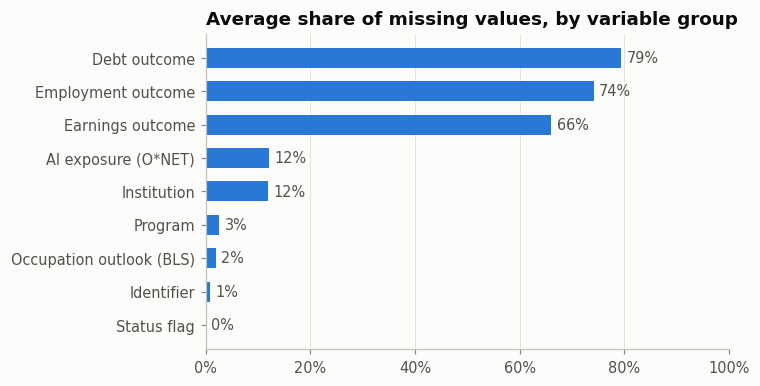

,earnings_4yr_status,earnings_1yr_status,earnings_5yr_status,debt_status
privacy_suppressed,169868,156343,158057,157429
reported,58112,52226,50512,46673
not_available,0,19411,19411,23878


In [5]:
miss = dictionary.groupby("group").pct_missing.agg(["mean", "max"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(miss.index, miss["mean"] / 100, color=BLUE, height=0.6)
for y, v in enumerate(miss["mean"]):
    ax.text(v / 100 + 0.01, y, f"{v:.0f}%", va="center", color=INK2)
ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, 1)
ax.set_title("Average share of missing values, by variable group")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

status = pd.concat({c: raw[c].value_counts() for c in GROUPS["Status flag"]}, axis=1).fillna(0).astype(int)
status

## 2. Cleaning
Each step is logged so the row counts can go straight into the report.

| Step | Rule | Why |
|---|---|---|
| 1 | Drop exact duplicate rows | Standard check |
| 2 | Drop `institution_control == "Foreign"` | Foreign universities (Edinburgh, McGill, …) have no state, tuition or admissions data and only a handful of reported earnings. They sit outside the U.S. comparison the project is about. |
| 3 | Collapse **shared-campus** records | When `outcomes_shared_across_campuses == 1`, every branch campus of an institution (same `opeid6`) repeats *identical* earnings and debt for the same field and credential. Keeping them all would count one outcome several times and let copies land in both train and test. We keep one representative per `opeid6 × CIP × credential`: the main campus if there is one, otherwise the lowest `unitid`. |
| 4 | Analysis sets are defined by target availability | Rows with a privacy-suppressed target can't be used for training or evaluation for that task. |

In [6]:
log = []
def record(step, frame, note=""):
    prev = log[-1]["rows"] if log else None
    log.append({"step": step, "rows": len(frame), "removed": (prev - len(frame)) if prev is not None else None, "note": note})

df = raw.copy()
record("0. Raw file", df)

df = df.drop_duplicates()
record("1. Exact duplicate rows", df)

df = df[df.institution_control != "Foreign"]
record("2. Foreign institutions", df, "outside U.S. scope")

KEY = ["opeid6", "cip_code_4digit", "credential_level"]
shared = df[df.outcomes_shared_across_campuses == 1]
check = shared.groupby(KEY)[["median_earnings_4yr_usd", "median_debt_usd"]].nunique(dropna=True)
assert (check <= 1).all().all(), "shared-campus groups should carry identical outcomes"
df = (df.sort_values(["is_main_campus", "unitid"], ascending=[False, True], na_position="last")
        .drop_duplicates(KEY, keep="first")
        .sort_index())
record("3. Shared-campus copies collapsed", df, "one record per opeid6 × CIP × credential")
assert not df.duplicated(KEY).any()
base = df.copy()

# analysis sets
REG_TARGET = "median_earnings_4yr_usd"
reg_all = base[base[REG_TARGET].notna()]
record("4a. Regression set: 4-yr earnings reported", reg_all)
log.append({"step": "4b. … of which bachelor's programs", "rows": int((reg_all.credential_level == 3).sum()),
            "removed": None, "note": "work-plan scope"})
cls_all = base[base.payment_to_income_pct_1yr.notna()]
log.append({"step": "4c. Classification set: debt-to-income reported", "rows": len(cls_all), "removed": None,
            "note": "from step 3"})

cleaning_log = pd.DataFrame(log)
cleaning_log.style.format({"rows": "{:,.0f}", "removed": lambda v: "" if pd.isna(v) else f"{v:,.0f}"})

,step,rows,removed,note
0,0. Raw file,"227,980",,
1,1. Exact duplicate rows,"227,980",0,
2,2. Foreign institutions,"223,318","4,662",outside U.S. scope
3,3. Shared-campus copies collapsed,"212,707","10,611",one record per opeid6 × CIP × credential
4,4a. Regression set: 4-yr earnings reported,"51,818","160,889",
5,4b. … of which bachelor's programs,"25,283",,work-plan scope
6,4c. Classification set: debt-to-income reported,"37,789",,from step 3


### 2.1 Sanity checks on values
Ranges, impossible values and internal consistency (for example, does `payment_to_income_pct_1yr` really equal 12 × monthly payment ÷ 1-year earnings?).

In [7]:
num_cols = ["median_earnings_1yr_usd", "median_earnings_4yr_usd", "median_earnings_5yr_usd", "median_debt_usd",
            "median_monthly_payment_usd", "debt_to_earnings_1yr", "payment_to_income_pct_1yr",
            "institution_admission_rate", "institution_avg_sat", "institution_tuition_in_state_usd",
            "occupation_median_wage_2024_usd", "ai_software_occupation_share", "earnings_cohort_size_4yr"]
display(base[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(2))

neg = (base.select_dtypes("number") < 0).sum()
print("Columns with negative values:", neg[neg > 0].to_dict())
print("Admission rate outside [0,1]:", ((base.institution_admission_rate < 0) | (base.institution_admission_rate > 1)).sum())

c = base.dropna(subset=["median_monthly_payment_usd", "median_earnings_1yr_usd", "payment_to_income_pct_1yr"])
recomputed = 12 * c.median_monthly_payment_usd / c.median_earnings_1yr_usd * 100
print(f"payment_to_income_pct_1yr = 12*payment/earnings_1yr: max abs diff {np.abs(recomputed - c.payment_to_income_pct_1yr).max():.2f} pts")
c = base.dropna(subset=[REG_TARGET, "national_median_earnings_4yr_usd"])
recomputed = (c[REG_TARGET] / c.national_median_earnings_4yr_usd - 1) * 100
print(f"earnings_vs_national_pct is computed from the target: max abs diff {np.abs(recomputed - c.earnings_vs_national_pct).max():.2f} pts")
print("national_median_earnings_4yr_usd values per CIP×credential:",
      base.groupby(["cip_code_4digit", "credential_level"]).national_median_earnings_4yr_usd.nunique().max())

,count,mean,std,min,1%,25%,50%,75%,99%,max
median_earnings_1yr_usd,46264.0,49757.19,24626.16,4506.00,14352.52,32665.75,44485.50,62148.25,129969.95,332843.00
median_earnings_4yr_usd,51818.0,65666.10,27887.39,6917.00,22130.16,47675.25,59554.50,77784.25,157678.26,336392.00
median_earnings_5yr_usd,44784.0,62692.34,28416.79,7826.00,19158.81,44718.75,56891.00,74367.00,158828.95,384547.00
median_debt_usd,40962.0,27707.11,27205.37,1287.00,5500.00,17367.50,22696.50,27000.00,162355.57,459525.00
median_monthly_payment_usd,40962.0,303.07,311.98,14.00,58.00,185.00,241.00,286.00,1846.78,5227.00
debt_to_earnings_1yr,37789.0,0.60,0.44,0.04,0.13,0.35,0.52,0.72,2.34,10.64
payment_to_income_pct_1yr,37789.0,7.84,5.95,0.48,1.67,4.56,6.66,9.29,31.87,145.28
institution_admission_rate,129391.0,0.70,0.24,0.00,0.04,0.60,0.77,0.88,1.00,1.00
institution_avg_sat,97710.0,1218.17,151.71,820.00,938.00,1102.00,1194.00,1317.00,1553.00,1560.00
institution_tuition_in_state_usd,197479.0,19393.98,19120.09,0.00,1156.00,5586.00,11060.00,30592.00,69350.00,72097.00


Columns with negative values: {'institution_latitude': 50, 'institution_longitude': 207502, 'earnings_vs_national_pct': 27135, 'earnings_growth_pct_1yr_to_5yr': 2006, 'occupation_growth_pct_2024_34': 25981, 'occupation_growth_pct_max': 417}
Admission rate outside [0,1]: 0
payment_to_income_pct_1yr = 12*payment/earnings_1yr: max abs diff 0.01 pts
earnings_vs_national_pct is computed from the target: max abs diff 0.05 pts
national_median_earnings_4yr_usd values per CIP×credential: 1


## 3. Leakage audit: columns that must **not** be predictors
A column leaks if it contains the target, is computed from it, or is only known *after* the outcome is observed. Using one inflates the scores and makes the model useless for a new program.

In [8]:
leak = [
    ("median_earnings_4yr_usd", "Regression target", "both"),
    ("earnings_vs_national_pct", "Computed directly from the target (verified above)", "both"),
    ("national_median_earnings_4yr_usd / _p25 / _p75", "Target summarised over every program in the same CIP × credential, test rows included. If wanted, rebuild it as a target encoding inside each CV fold.", "both"),
    ("median_earnings_1yr_usd, median_earnings_5yr_usd", "Same graduates' earnings at other horizons (r ≈ 0.91–0.94 with the target)", "regression"),
    ("earnings_growth_pct_1yr_to_5yr, earnings_trajectory_category", "Derived from 1-yr and 5-yr earnings", "both"),
    ("earnings_cohort_size_* , earnings_*_status, debt_status", "Only exist when an outcome is reported. Status flags literally say whether the target is present.", "both"),
    ("not_working_count_5yr, count_*_5yr, pct_*_5yr", "Post-graduation employment outcomes of the same cohort", "both"),
    ("debt_to_earnings_1yr, debt_to_earnings_4yr", "Contain earnings (and define the debt-risk label)", "both"),
    ("payment_to_income_pct_1yr", "Defines the classification label", "classification"),
    ("median_debt_usd, median_monthly_payment_usd, debt_borrower_count", "Numerator of the debt-risk label → leakage for classification. For earnings regression it's a judgment call: debt is fixed at graduation (before earnings) but only exists for reported cohorts.", "classification (judgment call for regression)"),
    ("program_id, unitid, opeid6, institution_name, institution_city", "Identifiers. opeid6 is used as the grouping key for the split, never as a feature.", "both"),
    ("cip_title, cip_family_code, credential_name, largest_linked_occupation_soc", "Duplicates of other columns (keep only one of each pair)", "both"),
]
pd.DataFrame(leak, columns=["column(s)", "reason", "exclude for"])

,column(s),reason,exclude for
0,median_earnings_4yr_usd,Regression target,both
1,earnings_vs_national_pct,Computed directly from the target (verified above),both
2,national_median_earnings_4yr_usd / _p25 / _p75,"Target summarised over every program in the same CIP × credential,...",both
3,"median_earnings_1yr_usd, median_earnings_5yr_usd",Same graduates' earnings at other horizons (r ≈ 0.91–0.94 with the...,regression
4,"earnings_growth_pct_1yr_to_5yr, earnings_trajectory_category",Derived from 1-yr and 5-yr earnings,both
5,"earnings_cohort_size_* , earnings_*_status, debt_status",Only exist when an outcome is reported. Status flags literally say...,both
6,"not_working_count_5yr, count_*_5yr, pct_*_5yr",Post-graduation employment outcomes of the same cohort,both
7,"debt_to_earnings_1yr, debt_to_earnings_4yr",Contain earnings (and define the debt-risk label),both
8,payment_to_income_pct_1yr,Defines the classification label,classification
9,"median_debt_usd, median_monthly_payment_usd, debt_borrower_count",Numerator of the debt-risk label → leakage for classification. For...,classification (judgment call for regression)


## 4. One institution-grouped train/test split for both problems
Programs from the same institution share tuition, selectivity, location and so on. If the same school appears in both train and test, the test score is optimistic. So the split is made on **institution groups (`opeid6`)**: 80% of institutions go to train, 20% to test. The split is done once on the full cleaned base, so the regression and classification sets inherit the same institutions. Five grouped CV folds are assigned inside train for tuning.

`split_ids.csv` holds the IDs so everyone uses identical rows. **From here on, every chart uses training rows only.** The test set is not looked at.

In [9]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
tr_idx, te_idx = next(gss.split(base, groups=base.opeid6))
base["split"] = "train"
base.iloc[te_idx, base.columns.get_loc("split")] = "test"

base["cv_fold"] = -1
tr_mask = base.split == "train"
for k, (_, va) in enumerate(GroupKFold(n_splits=5).split(base[tr_mask], groups=base.loc[tr_mask, "opeid6"])):
    base.loc[base[tr_mask].index[va], "cv_fold"] = k

assert set(base.loc[base.split == "train", "opeid6"]).isdisjoint(base.loc[base.split == "test", "opeid6"])

ids = base[["program_id", "opeid6", "credential_level", "split", "cv_fold"]].copy()
ids["in_regression_set"] = base[REG_TARGET].notna()
ids["in_classification_set"] = base.payment_to_income_pct_1yr.notna()
ids.to_csv(OUT_DIR / "split_ids.csv", index=False)

summary = pd.DataFrame({
    "all cleaned": base.split.value_counts(),
    "regression (all levels)": base[ids.in_regression_set.values].split.value_counts(),
    "regression (bachelor's)": base[ids.in_regression_set.values & (base.credential_level == 3)].split.value_counts(),
    "classification": base[ids.in_classification_set.values].split.value_counts(),
}).T
summary["test share"] = (summary["test"] / summary.sum(axis=1)).map("{:.1%}".format)
print("No institution appears in both train and test ✔   Saved split_ids.csv")
summary

No institution appears in both train and test ✔   Saved split_ids.csv


split,train,test,test share
all cleaned,166536,46171,21.7%
regression (all levels),40427,11391,22.0%
regression (bachelor's),19512,5771,22.8%
classification,29192,8597,22.8%


In [10]:
train = base[base.split == "train"]
reg_tr = train[train[REG_TARGET].notna()]
bach_tr = reg_tr[reg_tr.credential_level == 3]
cls_tr = train[train.payment_to_income_pct_1yr.notna()]
print(f"Training rows: regression {len(reg_tr):,} | bachelor's {len(bach_tr):,} | classification {len(cls_tr):,}")

Training rows: regression 40,427 | bachelor's 19,512 | classification 29,192


## 5. Regression target: median earnings 4 years after completion
### 5.1 Distribution

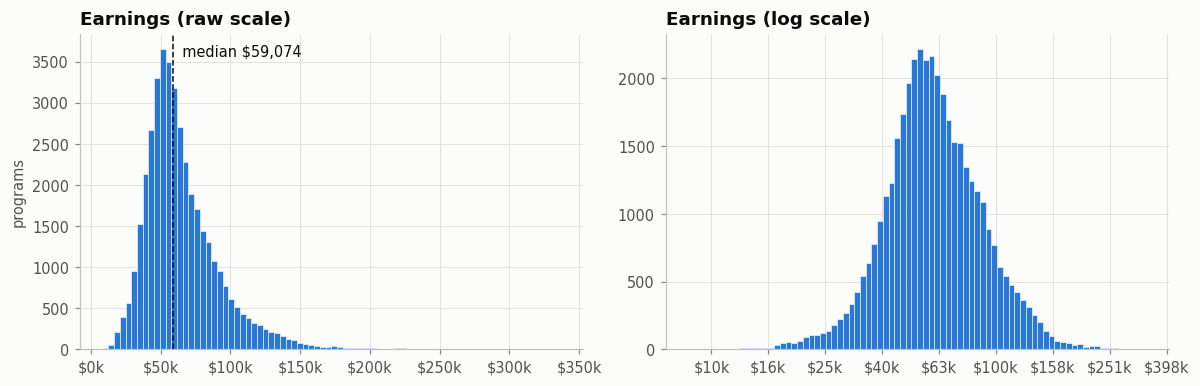

n=40,427  mean=$65,084  median=$59,074  sd=$27,641  skew=1.80  skew(log)=0.05  min=$8,305  max=$336,392


In [11]:
y = reg_tr[REG_TARGET]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(y, bins=80, color=BLUE, edgecolor="#fcfcfb", linewidth=0.4)
axes[0].axvline(y.median(), color=INK, lw=1, ls="--")
axes[0].text(y.median(), axes[0].get_ylim()[1] * 0.93, f"  median ${y.median():,.0f}", color=INK)
axes[0].xaxis.set_major_formatter(usd); axes[0].set_title("Earnings (raw scale)"); axes[0].set_ylabel("programs")
axes[1].hist(np.log10(y), bins=80, color=BLUE, edgecolor="#fcfcfb", linewidth=0.4)
axes[1].set_title("Earnings (log scale)")
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${10**v/1000:,.0f}k"))
plt.tight_layout(); plt.show()
print(f"n={len(y):,}  mean=${y.mean():,.0f}  median=${y.median():,.0f}  sd=${y.std():,.0f}  "
      f"skew={stats.skew(y):.2f}  skew(log)={stats.skew(np.log(y)):.2f}  min=${y.min():,.0f}  max=${y.max():,.0f}")

### 5.2 Credential level is the biggest single driver

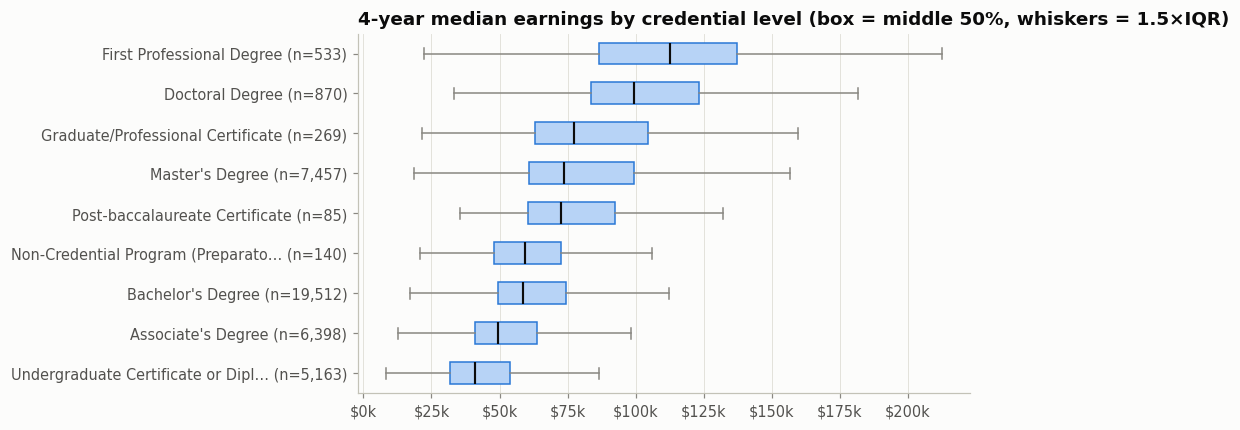

,count,25%,50%,75%
credential_name,,,,
Undergraduate Certificate or Diploma,5163.0,31784.0,41061.0,53781.0
Associate's Degree,6398.0,40895.0,49334.0,63896.0
Bachelor's Degree,19512.0,49486.0,58780.0,74534.0
Non-Credential Program (Preparatory Coursework/Teacher Certification),140.0,48065.0,59224.0,72610.0
Post-baccalaureate Certificate,85.0,60605.0,72411.0,92383.0
Master's Degree,7457.0,60981.0,73744.0,99331.0
Graduate/Professional Certificate,269.0,62923.0,77291.0,104440.0
Doctoral Degree,870.0,83415.0,99462.0,123234.0
First Professional Degree,533.0,86640.0,112580.0,137101.0


In [12]:
order = reg_tr.groupby("credential_name")[REG_TARGET].median().sort_values().index
data = [reg_tr.loc[reg_tr.credential_name == c, REG_TARGET] for c in order]
fig, ax = plt.subplots(figsize=(9, 4))
bp = ax.boxplot(data, vert=False, showfliers=False, widths=0.55, patch_artist=True,
                medianprops=dict(color=INK, lw=1.4), boxprops=dict(facecolor="#b7d3f6", edgecolor=BLUE),
                whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
ax.set_yticks(range(1, len(order) + 1), [f"{short(c, 34)} (n={len(d):,})" for c, d in zip(order, data)])
ax.xaxis.set_major_formatter(usd); ax.grid(axis="y", visible=False)
ax.set_title("4-year median earnings by credential level (box = middle 50%, whiskers = 1.5×IQR)")
plt.tight_layout(); plt.show()
reg_tr.groupby("credential_name")[REG_TARGET].describe()[["count", "25%", "50%", "75%"]].sort_values("50%").round(0)

### 5.3 Bachelor's programs: field of study matters, and so does the school within a field
Each dot is a field family's median. The line spans its middle 50% of programs. Only families with at least 50 training programs are shown.

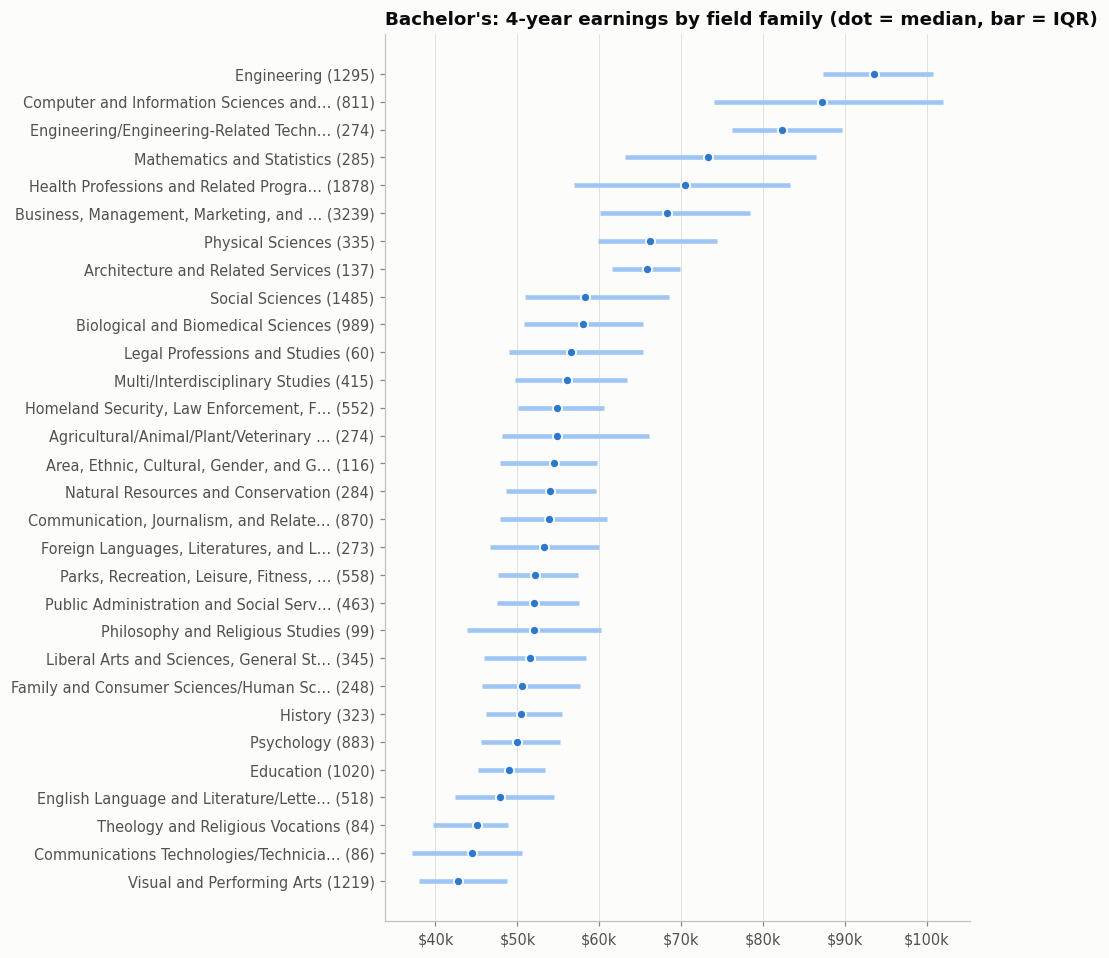

Highest-paying family: Engineering ($93,561);  lowest: Visual and Performing Arts ($42,798)


In [13]:
fam = (bach_tr.groupby("cip_family_title")[REG_TARGET]
       .agg(n="size", p25=lambda s: s.quantile(.25), median="median", p75=lambda s: s.quantile(.75))
       .query("n >= 50").sort_values("median"))
fig, ax = plt.subplots(figsize=(9, 0.26 * len(fam) + 1))
yy = np.arange(len(fam))
ax.hlines(yy, fam.p25, fam.p75, color="#9ec5f4", lw=3)
ax.plot(fam["median"], yy, "o", color=BLUE, ms=6, mec="#fcfcfb", mew=1.2)
ax.set_yticks(yy, [f"{short(t)} ({n})" for t, n in zip(fam.index, fam.n)])
ax.xaxis.set_major_formatter(usd); ax.grid(axis="y", visible=False)
ax.set_title("Bachelor's: 4-year earnings by field family (dot = median, bar = IQR)")
plt.tight_layout(); plt.show()
print(f"Highest-paying family: {fam.index[-1]} (${fam['median'].iloc[-1]:,.0f});  lowest: {fam.index[0]} (${fam['median'].iloc[0]:,.0f})")

In [14]:
# Same major, very different outcomes depending on the school
majors = {11.07: "Computer Science", 51.38: "Registered Nursing", 52.02: "Business Administration",
          42.01: "Psychology, General", 23.01: "English Language & Lit.", 14.19: "Mechanical Engineering",
          13.12: "Teacher Ed. (levels)", 45.10: "Political Science"}
rows = []
for code_, name in majors.items():
    s = bach_tr.loc[bach_tr.cip_code_4digit == code_, REG_TARGET]
    if len(s) >= 30:
        rows.append({"major": name, "n": len(s), "p10": s.quantile(.1), "median": s.median(), "p90": s.quantile(.9),
                     "p90/p10": s.quantile(.9) / s.quantile(.1)})
spread = pd.DataFrame(rows).sort_values("median")
display(spread.style.format({"p10": "${:,.0f}", "median": "${:,.0f}", "p90": "${:,.0f}", "p90/p10": "{:.2f}×"}))

cs_all = reg_all[(reg_all.credential_level == 3) & (reg_all.cip_code_4digit == 11.07)][REG_TARGET]
print(f"Check against the proposal (CS bachelor's, all cleaned rows, n={len(cs_all)}): "
      f"p10 ${cs_all.quantile(.1):,.0f} · median ${cs_all.median():,.0f} · p90 ${cs_all.quantile(.9):,.0f}")

,major,n,p10,median,p90,p90/p10
6,Teacher Ed. (levels),521,"$40,445","$47,767","$55,944",1.38×
4,English Language & Lit.,414,"$38,692","$48,148","$59,407",1.54×
3,"Psychology, General",773,"$41,029","$49,900","$59,299",1.45×
7,Political Science,402,"$50,795","$61,186","$76,110",1.50×
2,Business Administration,918,"$49,800","$64,028","$81,098",1.63×
1,Registered Nursing,684,"$73,592","$84,420","$104,549",1.42×
5,Mechanical Engineering,233,"$85,186","$91,435","$100,986",1.19×
0,Computer Science,252,"$73,221","$99,350","$143,542",1.96×


Check against the proposal (CS bachelor's, all cleaned rows, n=334): p10 $74,930 · median $98,882 · p90 $145,849


### 5.4 Institution characteristics (bachelor's programs)

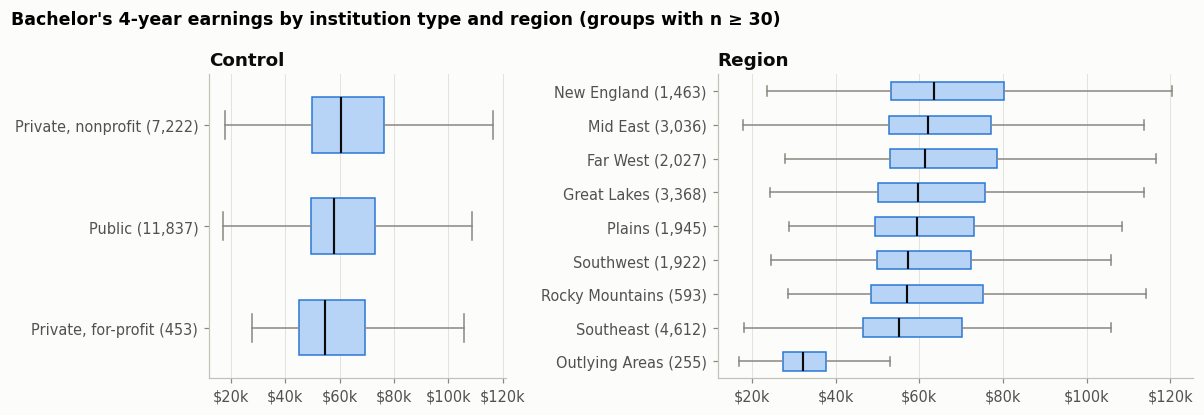

,size,median
distance_education,,
All credentials fully online,1553,58804.0
No credentials fully online,15311,58804.0
Not reported to IPEDS,753,57310.0
Some credentials fully online,1895,59181.0


,size,median
institution_is_hbcu,,
0.0,18695,59192.0
1.0,527,49299.0


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
for ax, col in zip(axes, ["institution_control", "institution_region"]):
    keep = bach_tr[col].value_counts().loc[lambda s: s >= 30].index
    order = bach_tr[bach_tr[col].isin(keep)].groupby(col)[REG_TARGET].median().sort_values().index
    data = [bach_tr.loc[bach_tr[col] == c, REG_TARGET] for c in order]
    ax.boxplot(data, vert=False, showfliers=False, widths=0.55, patch_artist=True,
               medianprops=dict(color=INK, lw=1.4), boxprops=dict(facecolor="#b7d3f6", edgecolor=BLUE),
               whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
    ax.set_yticks(range(1, len(order) + 1), [f"{c} ({len(d):,})" for c, d in zip(order, data)])
    ax.xaxis.set_major_formatter(usd); ax.grid(axis="y", visible=False)
    ax.set_title(col.replace("institution_", "").title())
plt.suptitle("Bachelor's 4-year earnings by institution type and region (groups with n ≥ 30)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()
display(bach_tr.groupby("distance_education")[REG_TARGET].agg(["size", "median"]).round(0))
display(bach_tr.groupby("institution_is_hbcu")[REG_TARGET].agg(["size", "median"]).round(0))

### 5.5 Numeric predictors vs. earnings (bachelor's)
Spearman ρ is used because the relationships are monotonic but not linear, and earnings are skewed.

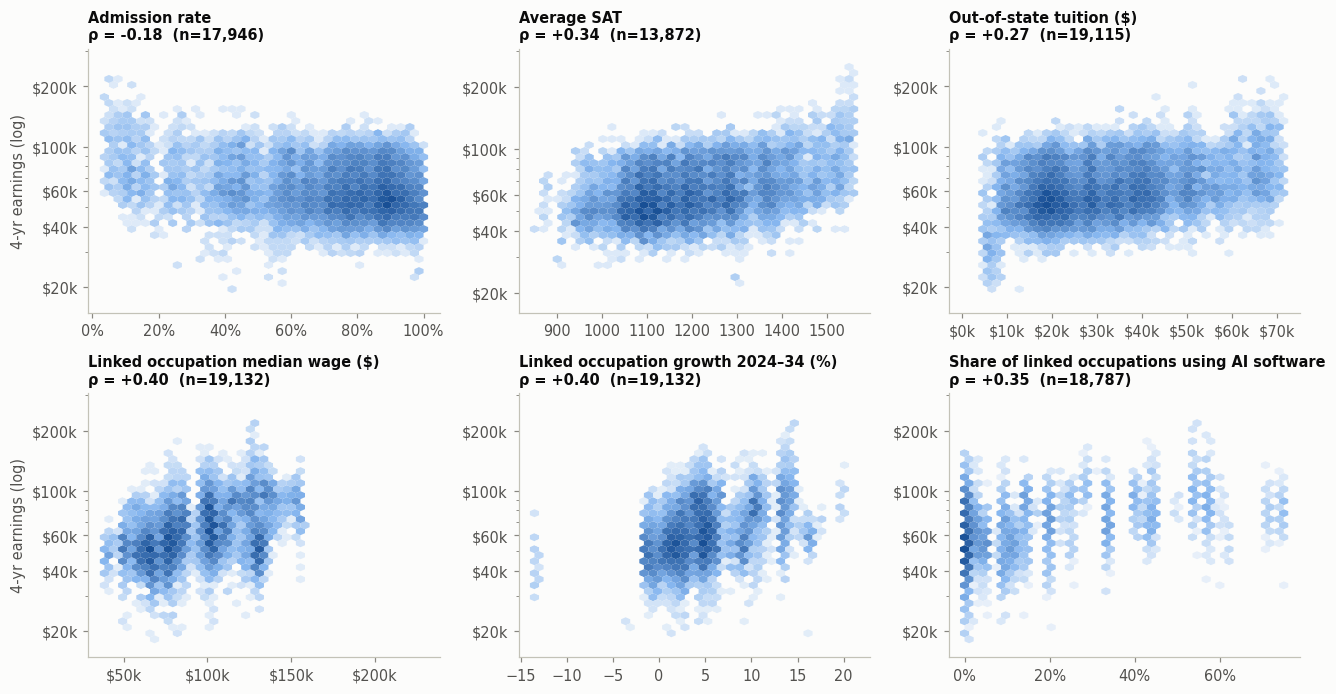

In [16]:
pairs = [("institution_admission_rate", "Admission rate"), ("institution_avg_sat", "Average SAT"),
         ("institution_tuition_out_state_usd", "Out-of-state tuition ($)"), ("occupation_median_wage_2024_usd", "Linked occupation median wage ($)"),
         ("occupation_growth_pct_2024_34", "Linked occupation growth 2024–34 (%)"), ("ai_software_occupation_share", "Share of linked occupations using AI software")]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
for ax, (col, label) in zip(axes.flat, pairs):
    d = bach_tr[[col, REG_TARGET]].dropna()
    ax.hexbin(d[col], d[REG_TARGET], gridsize=35, cmap=LinearSegmentedColormap.from_list("b", ["#fcfcfb", "#86b6ef", "#184f95"]),
              mincnt=1, bins="log", yscale="log", linewidths=0)
    rho = stats.spearmanr(d[col], d[REG_TARGET]).correlation
    ax.set_title(f"{label}\nρ = {rho:+.2f}  (n={len(d):,})", fontsize=9.5)
    ax.set_yticks([20_000, 40_000, 60_000, 100_000, 200_000]); ax.yaxis.set_minor_formatter(mtick.NullFormatter())
    ax.yaxis.set_major_formatter(usd); ax.grid(False)
    if "usd" in col: ax.xaxis.set_major_formatter(usd)
    if "share" in col or "rate" in col: ax.xaxis.set_major_formatter(pct)
axes[0, 0].set_ylabel("4-yr earnings (log)"); axes[1, 0].set_ylabel("4-yr earnings (log)")
plt.tight_layout(); plt.show()

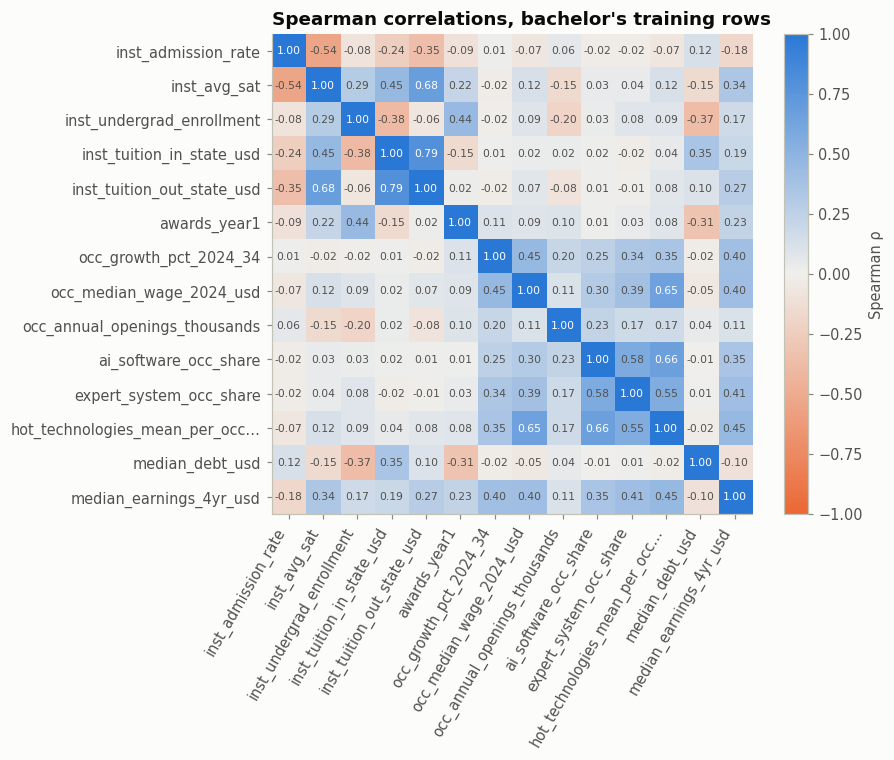

Correlation with target, strongest first:
hot_technologies_mean_per_occupation    0.45
expert_system_occupation_share          0.41
occupation_median_wage_2024_usd         0.40
occupation_growth_pct_2024_34           0.40
ai_software_occupation_share            0.35
institution_avg_sat                     0.34
institution_tuition_out_state_usd       0.27
awards_year1                            0.23
institution_tuition_in_state_usd        0.19
institution_admission_rate             -0.18
institution_undergrad_enrollment        0.17
occupation_annual_openings_thousands    0.11
median_debt_usd                        -0.10

Predictor pairs with |ρ| > 0.8 (redundant): []


In [17]:
NUM_CAND = ["institution_admission_rate", "institution_avg_sat", "institution_undergrad_enrollment",
            "institution_tuition_in_state_usd", "institution_tuition_out_state_usd", "awards_year1",
            "occupation_growth_pct_2024_34", "occupation_median_wage_2024_usd", "occupation_annual_openings_thousands",
            "ai_software_occupation_share", "expert_system_occupation_share", "hot_technologies_mean_per_occupation",
            "median_debt_usd", REG_TARGET]
corr = bach_tr[NUM_CAND].corr(method="spearman")
labels = [short(c.replace("institution_", "inst_").replace("occupation_", "occ_"), 30) for c in NUM_CAND]
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=60, ha="right"); ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else INK2)
ax.grid(False); plt.colorbar(im, fraction=0.04, label="Spearman ρ")
ax.set_title("Spearman correlations, bachelor's training rows")
plt.tight_layout(); plt.show()
print("Correlation with target, strongest first:")
print(corr[REG_TARGET].drop(REG_TARGET).sort_values(key=abs, ascending=False).round(2).to_string())
hi = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(NUM_CAND[:-1]) for b in NUM_CAND[i+1:-1] if abs(corr.loc[a, b]) > 0.8]
print("\nPredictor pairs with |ρ| > 0.8 (redundant):", hi)

### 5.6 Missing predictors, and whether the missingness carries information

In [18]:
PRED_CHECK = [c for c in NUM_CAND if c != REG_TARGET] + ["institution_region", "occupation_typical_entry_education"]
m = pd.DataFrame({"all levels": reg_tr[PRED_CHECK].isna().mean(), "bachelor's": bach_tr[PRED_CHECK].isna().mean()})
display(m.sort_values("all levels", ascending=False).style.format("{:.1%}"))

rows = []
for col in ["institution_avg_sat", "institution_admission_rate", "institution_tuition_in_state_usd"]:
    g = bach_tr.groupby(bach_tr[col].isna())[REG_TARGET].median()
    rows.append({"column": col, "median earnings if present": g.get(False), "median earnings if missing": g.get(True)})
print("Bachelor's: is missingness related to earnings? (yes → add a 'was missing' indicator)")
pd.DataFrame(rows).style.format({c: "${:,.0f}" for c in ["median earnings if present", "median earnings if missing"]})

,all levels,bachelor's
institution_avg_sat,48.8%,28.9%
institution_admission_rate,32.7%,8.0%
median_debt_usd,27.4%,14.0%
institution_tuition_out_state_usd,9.9%,2.0%
institution_tuition_in_state_usd,9.9%,2.0%
awards_year1,7.0%,3.3%
expert_system_occupation_share,4.4%,3.7%
hot_technologies_mean_per_occupation,4.4%,3.7%
ai_software_occupation_share,4.4%,3.7%
institution_undergrad_enrollment,3.7%,1.5%


Bachelor's: is missingness related to earnings? (yes → add a 'was missing' indicator)


,column,median earnings if present,median earnings if missing
0,institution_avg_sat,"$59,566","$56,986"
1,institution_admission_rate,"$59,012","$55,720"
2,institution_tuition_in_state_usd,"$58,854","$54,362"


### 5.7 Outliers

In [19]:
logy = np.log(reg_tr[REG_TARGET])
q1, q3 = logy.quantile([.25, .75]); iqr = q3 - q1
lo, hi = np.exp(q1 - 1.5 * iqr), np.exp(q3 + 1.5 * iqr)
print(f"IQR rule on log earnings flags {((reg_tr[REG_TARGET] < lo) | (reg_tr[REG_TARGET] > hi)).sum():,} programs "
      f"({((reg_tr[REG_TARGET] < lo) | (reg_tr[REG_TARGET] > hi)).mean():.1%}) outside ${lo:,.0f}–${hi:,.0f}")
cols = ["institution_name", "cip_title", "credential_name", REG_TARGET, "earnings_cohort_size_4yr"]
print("\nHighest earners:"); display(reg_tr.nlargest(8, REG_TARGET)[cols])
print("Lowest earners:"); display(reg_tr.nsmallest(8, REG_TARGET)[cols])
print("Lowest bachelor's earners:"); display(bach_tr.nsmallest(5, REG_TARGET)[cols])

IQR rule on log earnings flags 843 programs (2.1%) outside $22,814–$159,507

Highest earners:


,institution_name,cip_title,credential_name,median_earnings_4yr_usd,earnings_cohort_size_4yr
215240,Virginia Commonwealth University,Advanced/Graduate Dentistry and Oral Sciences,Master's Degree,336392.0,22.0
121529,Ohio State University-Main Campus,Dentistry,Master's Degree,329225.0,33.0
202597,University of Pennsylvania,Finance and Financial Management Services,Master's Degree,316195.0,121.0
144016,Saint Louis University,Advanced/Graduate Dentistry and Oral Sciences,Master's Degree,313933.0,25.0
80076,Johns Hopkins University,"Education, Other",Graduate/Professional Certificate,306793.0,17.0
80075,Johns Hopkins University,"Education, Other",Master's Degree,303202.0,18.0
202391,University of Pennsylvania,Law,First Professional Degree,302120.0,369.0
174176,Tufts University,Advanced/Graduate Dentistry and Oral Sciences,Graduate/Professional Certificate,296331.0,35.0


Lowest earners:


,institution_name,cip_title,credential_name,median_earnings_4yr_usd,earnings_cohort_size_4yr
73491,IVAEM College,Culinary Arts and Related Services,Undergraduate Certificate or Diploma,8305.0,21.0
119708,Nova College de Puerto Rico,Business Operations Support and Assistant Services,Undergraduate Certificate or Diploma,9447.0,17.0
53666,Emma's Beauty Academy-Mayaguez,Cosmetology and Related Personal Grooming Services,Undergraduate Certificate or Diploma,10574.0,158.0
119966,Nuvani Institute,Cosmetology and Related Personal Grooming Services,Undergraduate Certificate or Diploma,10791.0,24.0
131872,Pontifical Catholic University of Puerto Rico-Ponce,Culinary Arts and Related Services,Undergraduate Certificate or Diploma,11092.0,24.0
3106,American Educational College,Cosmetology and Related Personal Grooming Services,Undergraduate Certificate or Diploma,11582.0,114.0
127838,Pearl River Community College,Cosmetology and Related Personal Grooming Services,Undergraduate Certificate or Diploma,11844.0,21.0
104977,Modern Hairstyling Institute-Arecibo,Cosmetology and Related Personal Grooming Services,Undergraduate Certificate or Diploma,11971.0,71.0


Lowest bachelor's earners:


,institution_name,cip_title,credential_name,median_earnings_4yr_usd,earnings_cohort_size_4yr
203733,University of Puerto Rico-Mayaguez,Fine and Studio Arts,Bachelor's Degree,16981.0,27.0
227235,Yeshiva Gedolah Imrei Yosef D'spinka,Religion/Religious Studies,Bachelor's Degree,17806.0,22.0
39603,Columbus State University,Music,Bachelor's Degree,18218.0,21.0
146615,San Francisco Art Institute,Fine and Studio Arts,Bachelor's Degree,18418.0,27.0
176246,Universidad Central de Bayamon,"Psychology, General",Bachelor's Degree,18428.0,20.0


### 5.8 Earnings over time (1-yr → 5-yr). Descriptive only; these columns are leakage for prediction

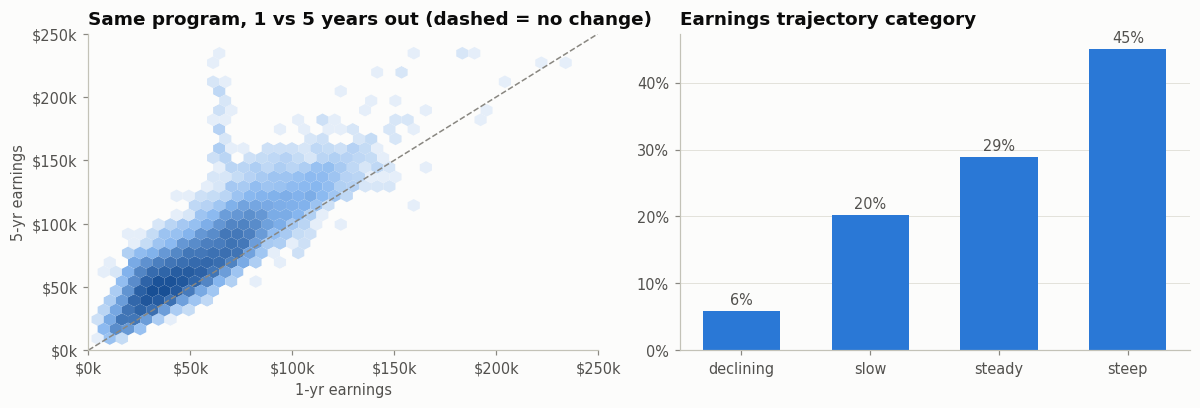

Median growth 1-yr → 5-yr: 31.2%
Pearson r between horizons:
                          median_earnings_1yr_usd  median_earnings_4yr_usd  median_earnings_5yr_usd
median_earnings_1yr_usd                    1.000                    0.912                    0.869
median_earnings_4yr_usd                    0.912                    1.000                    0.941
median_earnings_5yr_usd                    0.869                    0.941                    1.000


In [20]:
d = reg_tr.dropna(subset=["median_earnings_1yr_usd", "median_earnings_5yr_usd"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hexbin(d.median_earnings_1yr_usd, d.median_earnings_5yr_usd, gridsize=45, bins="log", mincnt=1,
               cmap=LinearSegmentedColormap.from_list("b", ["#fcfcfb", "#86b6ef", "#184f95"]), linewidths=0)
lim = [0, 250_000]; axes[0].plot(lim, lim, color=MUTED, lw=1, ls="--"); axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].xaxis.set_major_formatter(usd); axes[0].yaxis.set_major_formatter(usd); axes[0].grid(False)
axes[0].set_xlabel("1-yr earnings"); axes[0].set_ylabel("5-yr earnings"); axes[0].set_title("Same program, 1 vs 5 years out (dashed = no change)")
traj = reg_tr.earnings_trajectory_category.value_counts(normalize=True).reindex(["declining", "slow", "steady", "steep"])
axes[1].bar(traj.index, traj.values, color=BLUE, width=0.6); axes[1].yaxis.set_major_formatter(pct)
for x, v in enumerate(traj.values): axes[1].text(x, v + 0.01, f"{v:.0%}", ha="center", color=INK2)
axes[1].set_title("Earnings trajectory category"); axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print(f"Median growth 1-yr → 5-yr: {reg_tr.earnings_growth_pct_1yr_to_5yr.median():.1f}%")
print("Pearson r between horizons:\n", reg_tr[["median_earnings_1yr_usd", "median_earnings_4yr_usd", "median_earnings_5yr_usd"]].corr().round(3))

## 6. Classification target: high debt-risk
`payment_to_income_pct_1yr` is the annual loan payment as a % of first-year earnings (verified in 2.1). The federal *gainful-employment* rule treats **> 8%** as a failing debt-to-earnings rate, so that is the natural cut-off. But the proposal expects "only a small share" to be high-risk, so the threshold choice changes the class balance a lot. The table below shows how much.

,threshold,share high-risk,n high-risk
0,> 8% (gainful-employment standard),35.7%,"10,435"
1,> 10%,20.6%,"5,999"
2,> 12%,11.9%,"3,485"
3,> 20%,3.0%,865


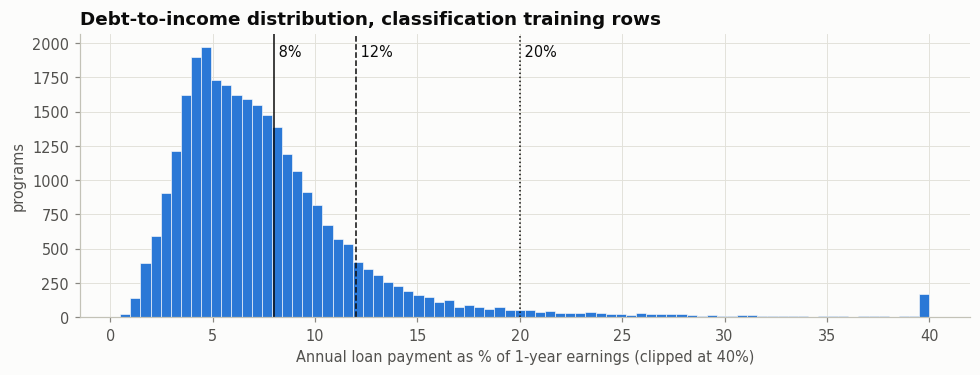

In [21]:
p = cls_tr.payment_to_income_pct_1yr
thr = pd.DataFrame({"threshold": ["> 8% (gainful-employment standard)", "> 10%", "> 12%", "> 20%"],
                    "share high-risk": [(p > t).mean() for t in [8, 10, 12, 20]],
                    "n high-risk": [(p > t).sum() for t in [8, 10, 12, 20]]})
display(thr.style.format({"share high-risk": "{:.1%}", "n high-risk": "{:,}"}))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(p.clip(upper=40), bins=80, color=BLUE, edgecolor="#fcfcfb", linewidth=0.4)
for t, ls in [(8, "-"), (12, "--"), (20, ":")]:
    ax.axvline(t, color=INK, lw=1, ls=ls); ax.text(t, ax.get_ylim()[1] * 0.92, f" {t}%", color=INK)
ax.set_xlabel("Annual loan payment as % of 1-year earnings (clipped at 40%)"); ax.set_ylabel("programs")
ax.set_title("Debt-to-income distribution, classification training rows")
plt.tight_layout(); plt.show()

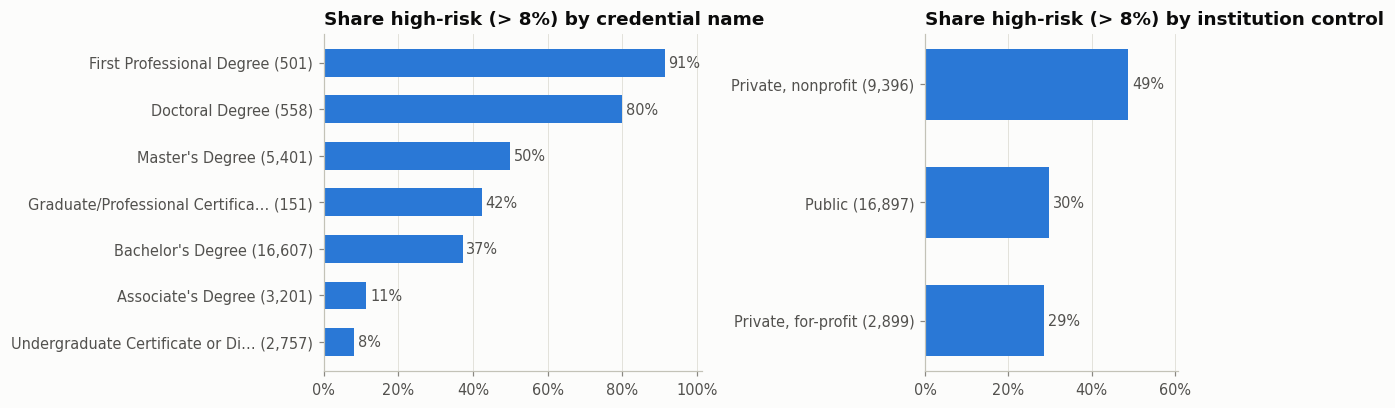

In [22]:
RISK_T = 8
cls_tr = cls_tr.assign(high_risk=(cls_tr.payment_to_income_pct_1yr > RISK_T).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
for ax, col in zip(axes, ["credential_name", "institution_control"]):
    r = cls_tr.groupby(col).high_risk.agg(["mean", "size"]).query("size >= 50").sort_values("mean")
    ax.barh([f"{short(i, 32)} ({n:,})" for i, n in zip(r.index, r["size"])], r["mean"], color=BLUE, height=0.6)
    for yv, v in enumerate(r["mean"]): ax.text(v + 0.01, yv, f"{v:.0%}", va="center", color=INK2)
    ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, max(1, r["mean"].max() + 0.1) if r["mean"].max() > .9 else r["mean"].max() + 0.12)
    ax.grid(axis="y", visible=False); ax.set_title(f"Share high-risk (> {RISK_T}%) by {col.replace('_', ' ')}")
plt.tight_layout(); plt.show()

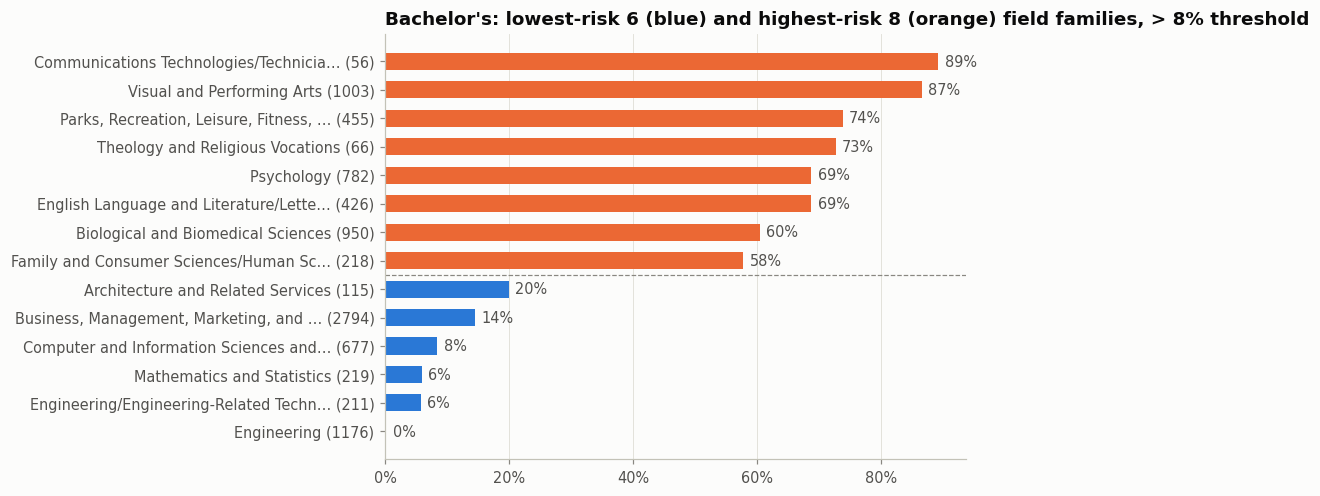

Bachelor's high-risk share: 37.2%  (n=16,607)


In [23]:
bc = cls_tr[cls_tr.credential_level == 3]
fam = bc.groupby("cip_family_title").high_risk.agg(["mean", "size"]).query("size >= 50").sort_values("mean")
show = pd.concat([fam.head(6), fam.tail(8)])
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh([f"{short(i)} ({n})" for i, n in zip(show.index, show["size"])], show["mean"],
        color=[BLUE] * 6 + [ORANGE] * 8, height=0.6)
for yv, v in enumerate(show["mean"]): ax.text(v + 0.01, yv, f"{v:.0%}", va="center", color=INK2)
ax.axhline(5.5, color=MUTED, lw=0.8, ls="--")
ax.xaxis.set_major_formatter(pct); ax.grid(axis="y", visible=False)
ax.set_title(f"Bachelor's: lowest-risk 6 (blue) and highest-risk 8 (orange) field families, > {RISK_T}% threshold")
plt.tight_layout(); plt.show()
print(f"Bachelor's high-risk share: {bc.high_risk.mean():.1%}  (n={len(bc):,})")

In [24]:
cols = ["institution_admission_rate", "institution_avg_sat", "institution_tuition_in_state_usd", "institution_tuition_out_state_usd",
        "occupation_median_wage_2024_usd", "occupation_growth_pct_2024_34", "ai_software_occupation_share", "awards_year1"]
cmp = cls_tr.groupby("high_risk")[cols].median().T
cmp.columns = ["not high-risk (median)", "high-risk (median)"]
cmp["Spearman ρ with debt-to-income"] = [stats.spearmanr(*cls_tr[[c, "payment_to_income_pct_1yr"]].dropna().T.values).correlation for c in cols]
cmp.round(3)

,not high-risk (median),high-risk (median),Spearman ρ with debt-to-income
institution_admission_rate,0.782,0.788,0.049
institution_avg_sat,1191.000,1180.000,-0.092
institution_tuition_in_state_usd,11688.000,15480.000,0.296
institution_tuition_out_state_usd,23638.000,29630.000,0.221
occupation_median_wage_2024_usd,85697.000,79063.000,-0.066
occupation_growth_pct_2024_34,4.890,4.040,-0.177
ai_software_occupation_share,0.000,0.000,-0.155
awards_year1,52.000,36.000,-0.213


### 6.1 What actually drives debt-risk? Debt or earnings?

In [25]:
rows = []
for name, d in [("All credential levels", cls_tr), ("Bachelor's only", cls_tr[cls_tr.credential_level == 3])]:
    rows.append({"set": name, "n": len(d),
                 "median debt": d.median_debt_usd.median(),
                 "debt IQR": f"${d.median_debt_usd.quantile(.25):,.0f}–${d.median_debt_usd.quantile(.75):,.0f}",
                 "ρ (debt-to-income, debt)": stats.spearmanr(d.payment_to_income_pct_1yr, d.median_debt_usd).correlation,
                 "ρ (debt-to-income, 1-yr earnings)": stats.spearmanr(d.payment_to_income_pct_1yr, d.median_earnings_1yr_usd).correlation})
display(pd.DataFrame(rows).style.format({"n": "{:,}", "median debt": "${:,.0f}", "ρ (debt-to-income, debt)": "{:+.2f}",
                                         "ρ (debt-to-income, 1-yr earnings)": "{:+.2f}"}).hide(axis="index"))
print("Bachelor's federal borrowing is close to capped, so debt barely varies. Among bachelor's programs, 'high debt-risk' "
      "mostly means 'low first-year earnings'. Across all levels, debt itself matters more.")

set,n,median debt,debt IQR,"ρ (debt-to-income, debt)","ρ (debt-to-income, 1-yr earnings)"
All credential levels,"29,192","$22,604","$17,481–$27,000",+0.66,-0.35
Bachelor's only,"16,607","$22,647","$19,500–$26,000",+0.49,-0.85


Bachelor's federal borrowing is close to capped, so debt barely varies. Among bachelor's programs, 'high debt-risk' mostly means 'low first-year earnings'. Across all levels, debt itself matters more.


## 7. Job outlook and AI exposure

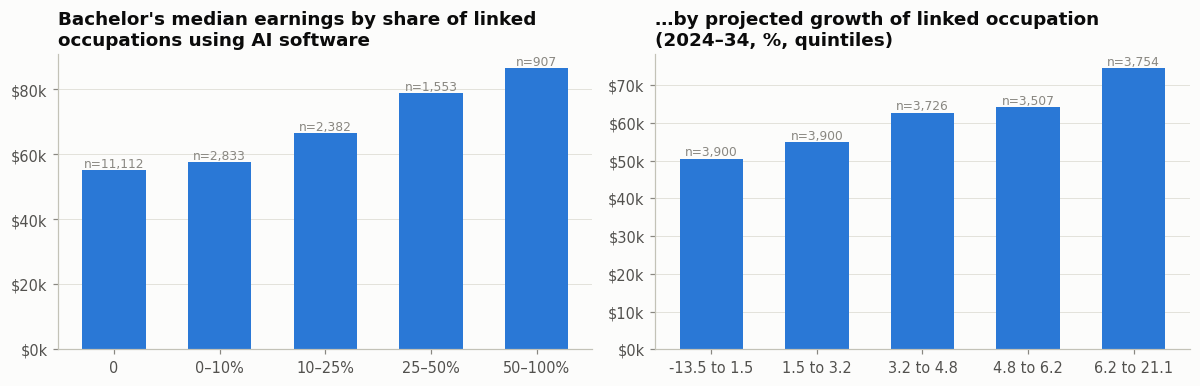

In [26]:
b = bach_tr.dropna(subset=["ai_software_occupation_share"]).copy()
b["ai_bin"] = pd.cut(b.ai_software_occupation_share, [-0.001, 0, 0.1, 0.25, 0.5, 1.0],
                     labels=["0", "0–10%", "10–25%", "25–50%", "50–100%"])
g = b.groupby("ai_bin", observed=True)[REG_TARGET].agg(["size", "median"])
b["growth_bin"] = pd.qcut(b.occupation_growth_pct_2024_34, 5, duplicates="drop")
g2 = b.groupby("growth_bin", observed=True)[REG_TARGET].agg(["size", "median"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(g.index.astype(str), g["median"], color=BLUE, width=0.6)
axes[0].set_title("Bachelor's median earnings by share of linked\noccupations using AI software"); axes[0].yaxis.set_major_formatter(usd)
axes[1].bar([f"{i.left:.1f} to {i.right:.1f}" for i in g2.index], g2["median"], color=BLUE, width=0.6)
axes[1].set_title("…by projected growth of linked occupation\n(2024–34, %, quintiles)"); axes[1].yaxis.set_major_formatter(usd)
for ax, gg in zip(axes, [g, g2]):
    ax.grid(axis="x", visible=False)
    for x, (n, v) in enumerate(zip(gg["size"], gg["median"])): ax.text(x, v + 800, f"n={n:,}", ha="center", color=MUTED, fontsize=8)
plt.tight_layout(); plt.show()

## 8. Preprocessing pipelines (fit on training folds only)
**Candidate predictor set.** This is a proposal for the group to confirm, not a final decision. For the bachelor's scope there are 14 predictors. Add `credential_level` when modelling all levels.

| Type | Columns | Treatment |
|---|---|---|
| Numeric (9) | admission rate, avg SAT, undergrad enrollment, in-state tuition, out-state tuition, awards_year1, occupation growth, occupation median wage, AI-software share | median impute + **missing indicator**; scaled for linear models only |
| Binary (1) | HBCU | most-frequent impute |
| Categorical (4) | institution control, CIP family, region, distance education | "missing" category + one-hot (rare levels < 20 grouped) |

Everything sits inside a scikit-learn `Pipeline`, so `cross_val_score` re-fits imputation, encoding and scaling **inside each fold**. Nothing is imputed globally.

In [27]:
NUM = ["institution_admission_rate", "institution_avg_sat", "institution_undergrad_enrollment",
       "institution_tuition_in_state_usd", "institution_tuition_out_state_usd", "awards_year1",
       "occupation_growth_pct_2024_34", "occupation_median_wage_2024_usd", "ai_software_occupation_share"]
BIN = ["institution_is_hbcu"]
CAT = ["institution_control", "cip_family_title", "institution_region", "distance_education"]

def make_preprocessor(scale=True, extra_cat=()):
    num_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUM),
        ("bin", SimpleImputer(strategy="most_frequent"), BIN),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                                                   sparse_output=False))]), CAT + list(extra_cat)),
    ])

pre_linear = make_preprocessor(scale=True)    # Linear / Ridge / Lasso / Logistic
pre_tree   = make_preprocessor(scale=False)   # Decision tree / Random forest / Gradient boosting

X_bach = bach_tr[NUM + BIN + CAT]
Xt = pre_linear.fit_transform(X_bach)
print(f"Bachelor's training matrix after preprocessing: {Xt.shape[0]:,} rows × {Xt.shape[1]} features")
print("Any NaN left?", np.isnan(Xt).any())

Bachelor's training matrix after preprocessing: 19,512 rows × 70 features
Any NaN left? False


**Reference point for the modelling week.** A mean-only baseline, scored with the shared grouped CV folds. Every model should beat this.

In [ ]:
folds = list(GroupKFold(n_splits=5).split(X_bach, groups=bach_tr.opeid6))
base_mae = -cross_val_score(Pipeline([("pre", pre_linear), ("m", DummyRegressor())]), X_bach, bach_tr[REG_TARGET],
                            cv=folds, scoring="neg_mean_absolute_error")
print(f"Bachelor's mean-baseline CV MAE: ${base_mae.mean():,.0f} (± ${base_mae.std():,.0f} across folds)")

Bachelor's mean-baseline CV MAE: $15,799 (± $297 across folds)


## 9. Summary of findings
*All numbers below are from the training split (80% of institutions) unless they describe the full file.*

### The data
- **72 variables, 227,980 rows** (this fills the "[__] variables" blank in the proposal). One row = institution × 4-digit CIP field × credential level.
- **Cleaning removed 15,273 rows → 212,707 programs.** 4,662 were foreign institutions and 10,611 were duplicate branch-campus copies of shared outcomes (same earnings repeated across campuses).
- **Most outcomes are privacy-suppressed, not randomly missing.** 4-year earnings are reported for 51,818 programs (24%), 25,283 of them bachelor's. Debt-to-income is reported for 37,789 programs.
- **Leakage is a real risk.** About 30 columns are outcomes or derived from outcomes. The subtle ones are `national_median_earnings_4yr_usd` (the target averaged over the program's field, test rows included) and `earnings_vs_national_pct` (computed directly from the target).
- **Split:** 80/20 by institution, saved in `split_ids.csv` with five grouped CV folds. No institution is in both train and test.

### Regression target: 4-year median earnings
| Finding | Evidence |
|---|---|
| Strongly right-skewed | skew 1.80 raw vs 0.05 on log scale; median $59k, max $336k → consider a log target |
| Credential level is the biggest driver | median $41k (undergrad certificate) → $59k (bachelor's) → $74k (master's) → $99k (doctoral) → $113k (first professional) |
| Field matters a lot for bachelor's | Engineering $94k vs Visual & Performing Arts $43k |
| The school matters within a field | CS bachelor's p10–p90: $73k–$144k (≈ the proposal's "$75k–$146k" claim); Mechanical Eng. only $85k–$101k |
| Location: territories are far lower | Outlying Areas (Puerto Rico etc.) median ≈ $32k vs $55–64k for mainland regions |
| Strongest numeric signals are occupation-level | Spearman ρ: hot technologies 0.45, expert-system share 0.41, occupation wage 0.40, occupation growth 0.40, AI-software share 0.35, avg SAT 0.34 |
| AI exposure ≈ a proxy for tech/engineering fields | AI share correlates 0.30–0.66 with occupation wage and tech measures, so don't read it as causal |
| No severe multicollinearity | no predictor pair has absolute ρ above 0.8; in-state vs out-of-state tuition is 0.79 |
| Missingness carries information | SAT missing for 29% of bachelor's rows (49% across all levels); programs with missing SAT, admission rate or tuition earn less → keep missing-indicator columns |
| Outliers are real, not errors | 2.1% flagged (IQR on log); the top are dentistry master's ($336k) and Penn Law ($302k), the bottom are cosmetology certificates (~$10k) → keep them, use MAE or a log target |
| Online delivery makes no difference | medians $58.8k–$59.2k across distance-education groups |
| **Baseline to beat** | mean-only model, bachelor's, grouped 5-fold CV: **MAE ≈ $15,800** |

### Classification target: high debt-risk
- At the federal **8% debt-to-income** standard, **36% of programs are high-risk** (37% of bachelor's). That is not the "small share" the proposal describes. A 12% cut-off gives 12% and 20% gives 3%. **The threshold is a group decision.**
- Risk climbs with credential level: 8% for undergrad certificates, 50% for master's, 91% for first professional degrees.
- By field (bachelor's): Visual & Performing Arts 87% and Psychology 69%, vs Engineering 0% and Computer Science 8%.
- **Important for scope.** Bachelor's borrowing is nearly capped (median $22.6k, IQR roughly $19.5k–$26k). So for bachelor's, debt-risk is driven almost entirely by low first-year earnings (ρ = −0.85 vs +0.49 for debt). A bachelor's-only classifier would mostly restate the earnings regression. Across all credential levels, debt varies much more (ρ = +0.66), so the classification problem only adds value if we keep all levels.

### Questions to settle at next week's meeting
1. **Scope:** bachelor's only (the work plan) or all credential levels (the proposal)?
2. **Classification:** keep it? If yes, which threshold (8% / 12%), and should it cover all levels (see above)?
3. **Predictors:** confirm the 14 proposed in section 8, and whether `median_debt_usd` is allowed for the earnings regression.
4. **Target transform:** raw earnings or log(earnings)?
5. **Everyone uses `split_ids.csv`** so results are comparable.